In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
)

# Standard UCI Heart Disease (Cleveland) dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

# Read data, treating '?' as NaN
df = pd.read_csv(url, header=None, names=columns, na_values='?')
# Binarize target: 0 = absent, >0 = present
df['target'] = (df['target'] > 0).astype(int)

In [ ]:
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


target
0    164
1    139
Name: count, dtype: int64
target
0    54.13
1    45.87
Name: proportion, dtype: float64


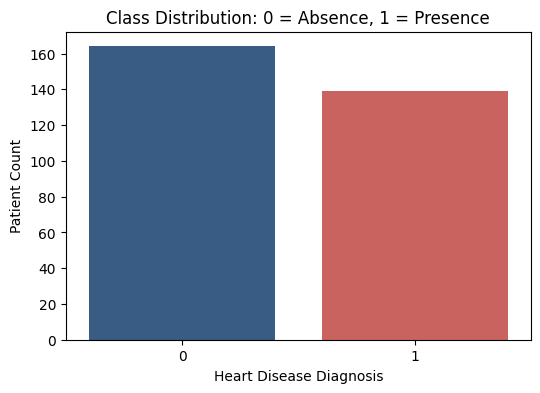

In [ ]:
print(df['target'].value_counts())
print((df['target'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette=['#2b5c8f', '#d9534f'], hue='target', legend=False)
plt.title("Class Distribution: 0 = Absence, 1 = Presence")
plt.xlabel("Heart Disease Diagnosis")
plt.ylabel("Patient Count")
plt.show()

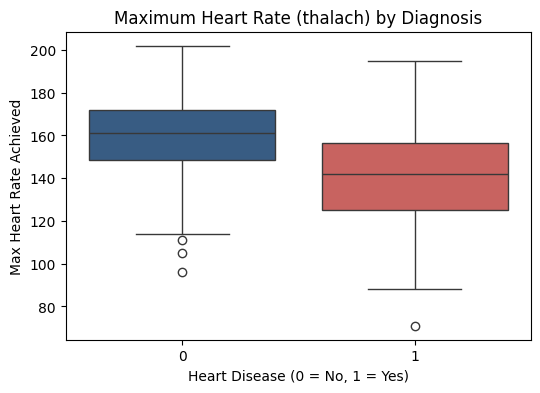

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='target', y='thalach', data=df, palette=['#2b5c8f', '#d9534f'], hue='target', legend=False)
plt.title("Maximum Heart Rate (thalach) by Diagnosis")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Max Heart Rate Achieved")
plt.show()

In [ ]:
print("Missing values per column:\n", df.isnull().sum())
print("\nTotal duplicate rows:", df.duplicated().sum())

# Handle missing values (if any) and drop duplicates
df = df.dropna()
df = df.drop_duplicates().reset_index(drop=True)
print("\nShape after handling missing values & duplicates:", df.shape)

Missing values per column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total duplicate rows: 0

Shape after handling missing values & duplicates: (297, 14)


Outlier rows in 'chol': 5
Disease rate in outliers: 40.00%
Disease rate overall:     46.13%


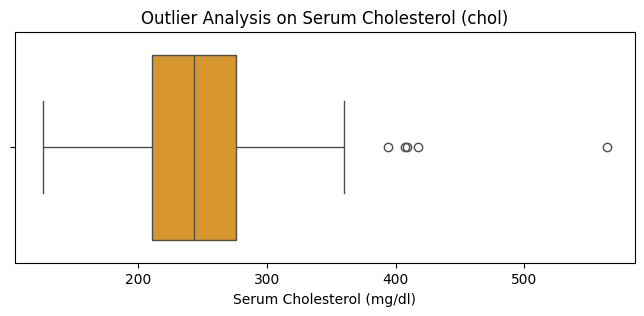

In [ ]:
q1, q3 = df['chol'].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = df[df['chol'] > upper]
print(f"Outlier rows in 'chol': {len(outliers)}")
print("Disease rate in outliers: %.2f%%" % (outliers['target'].mean() * 100))
print("Disease rate overall:     %.2f%%" % (df['target'].mean() * 100))

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['chol'], color='#f39c12')
plt.title("Outlier Analysis on Serum Cholesterol (chol)")
plt.xlabel("Serum Cholesterol (mg/dl)")
plt.show()

In [ ]:
# Discretize continuous age into clinical cohorts
bins = [0, 44, 54, 64, 100]
labels = ['<45 (Young)', '45-54 (Middle-aged)', '55-64 (Senior)', '65+ (Elderly)']
df['age_cohort'] = pd.cut(df['age'], bins=bins, labels=labels)

# Display cross-tabulation table
cohort_summary = df.groupby('age_cohort', observed=True)['target'].agg(
    Total_Patients='count',
    Disease_Cases='sum',
    Prevalence_Rate='mean'
)
cohort_summary['Prevalence_Rate'] = (cohort_summary['Prevalence_Rate'] * 100).round(2).astype(str) + '%'
cohort_summary

,Total_Patients,Disease_Cases,Prevalence_Rate
age_cohort,,,
<45 (Young),53,13,24.53%
45-54 (Middle-aged),85,29,34.12%
55-64 (Senior),118,75,63.56%
65+ (Elderly),41,20,48.78%


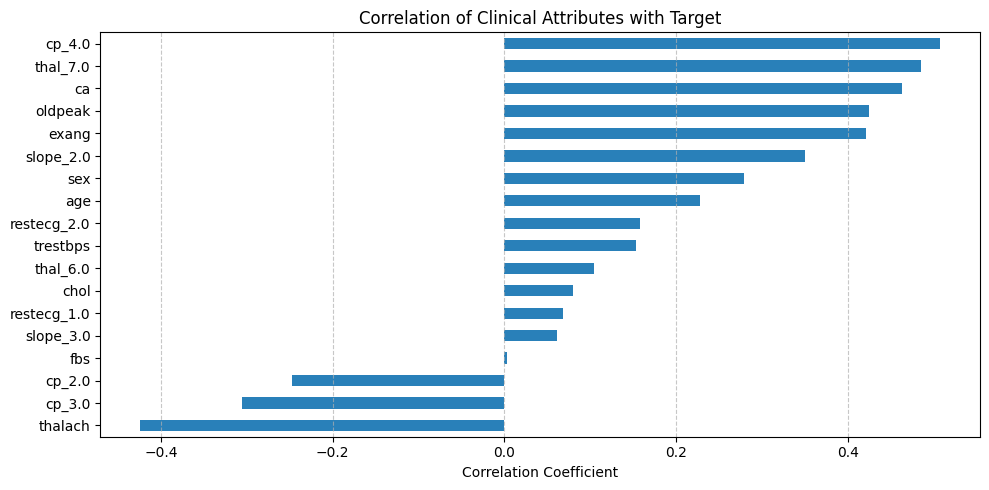

In [ ]:
# Convert nominal variables to dummy indicators before computing correlations
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
df_encoded = pd.get_dummies(df.drop(columns=['age_cohort']), columns=categorical_cols, drop_first=True)

corr = df_encoded.corr()['target'].drop('target').sort_values()

plt.figure(figsize=(10, 5))
corr.plot(kind='barh', color='#2980b9')
plt.title("Correlation of Clinical Attributes with Target")
plt.xlabel("Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

# Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Standardize continuous attributes
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print(f"X_train Shape: {X_train_scaled.shape} | X_test Shape: {X_test_scaled.shape}")
print("Training target balance:\n", y_train.value_counts().to_dict())
print("Test target balance:\n", y_test.value_counts().to_dict())

X_train Shape: (237, 18) | X_test Shape: (60, 18)
Training target balance:
 {0: 128, 1: 109}
Test target balance:
 {0: 32, 1: 28}


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
}

preds = {}
probas = {}
rows = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds[name] = model.predict(X_test_scaled)
    probas[name] = model.predict_proba(X_test_scaled)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1-score": f1_score(y_test, preds[name]),
        "ROC-AUC": roc_auc_score(y_test, probas[name])
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8667,0.8846,0.8214,0.8519,0.9498
Decision Tree,0.7667,0.8889,0.5714,0.6957,0.7985
Random Forest,0.8167,0.8400,0.7500,0.7925,0.9330


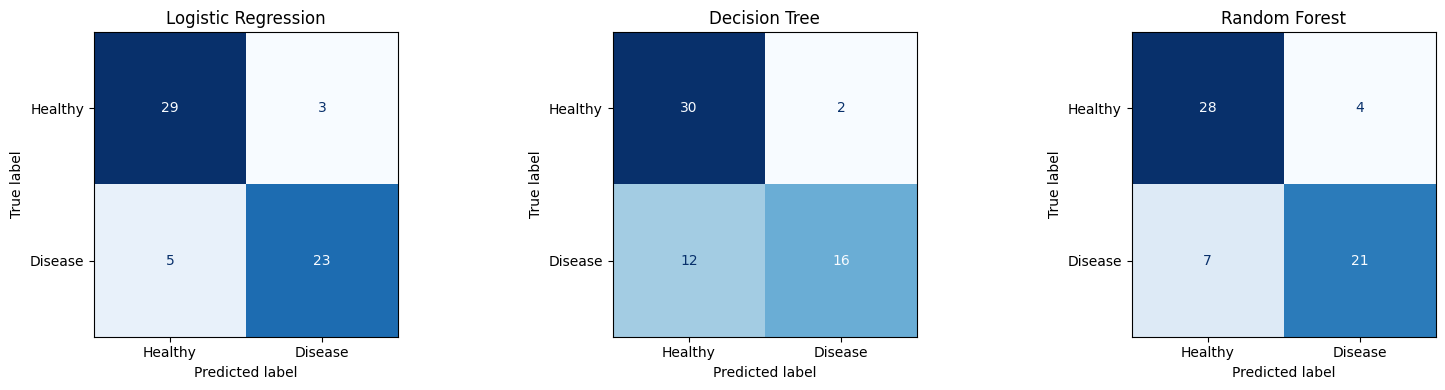

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Healthy", "Disease"])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

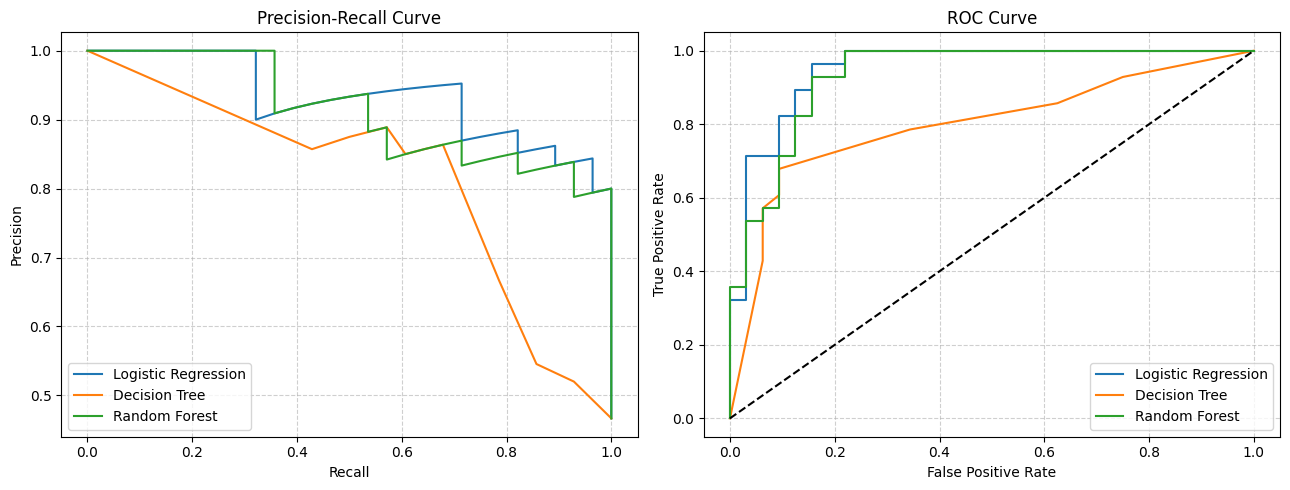

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, proba in probas.items():
    # Precision-Recall Curve
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(r, p, label=name)

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=name)

axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curve")
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

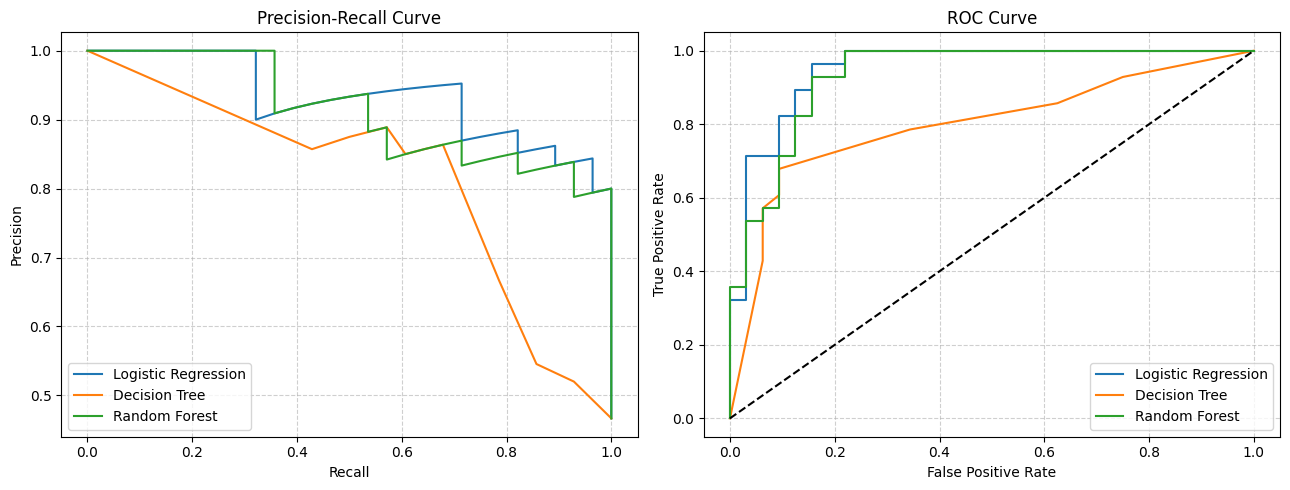

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, proba in probas.items():
    # Precision-Recall Curve
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(r, p, label=name)

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=name)

axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curve")
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

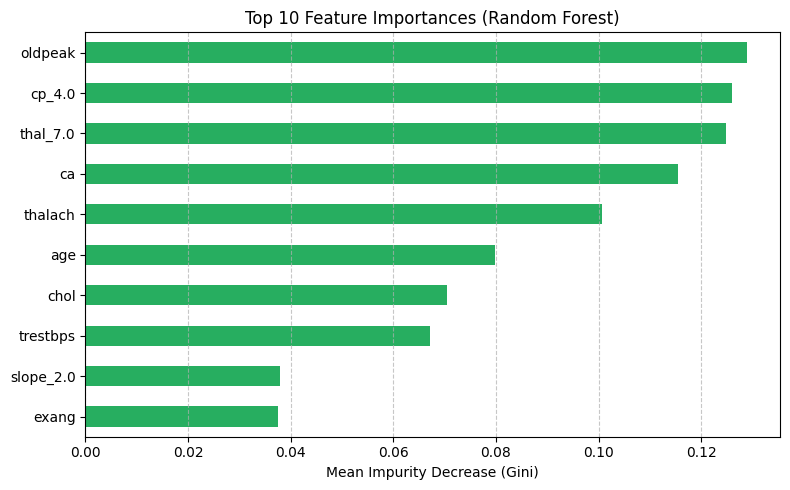

In [ ]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances.head(10).plot(kind='barh', color='#27ae60').invert_yaxis()
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Mean Impurity Decrease (Gini)")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

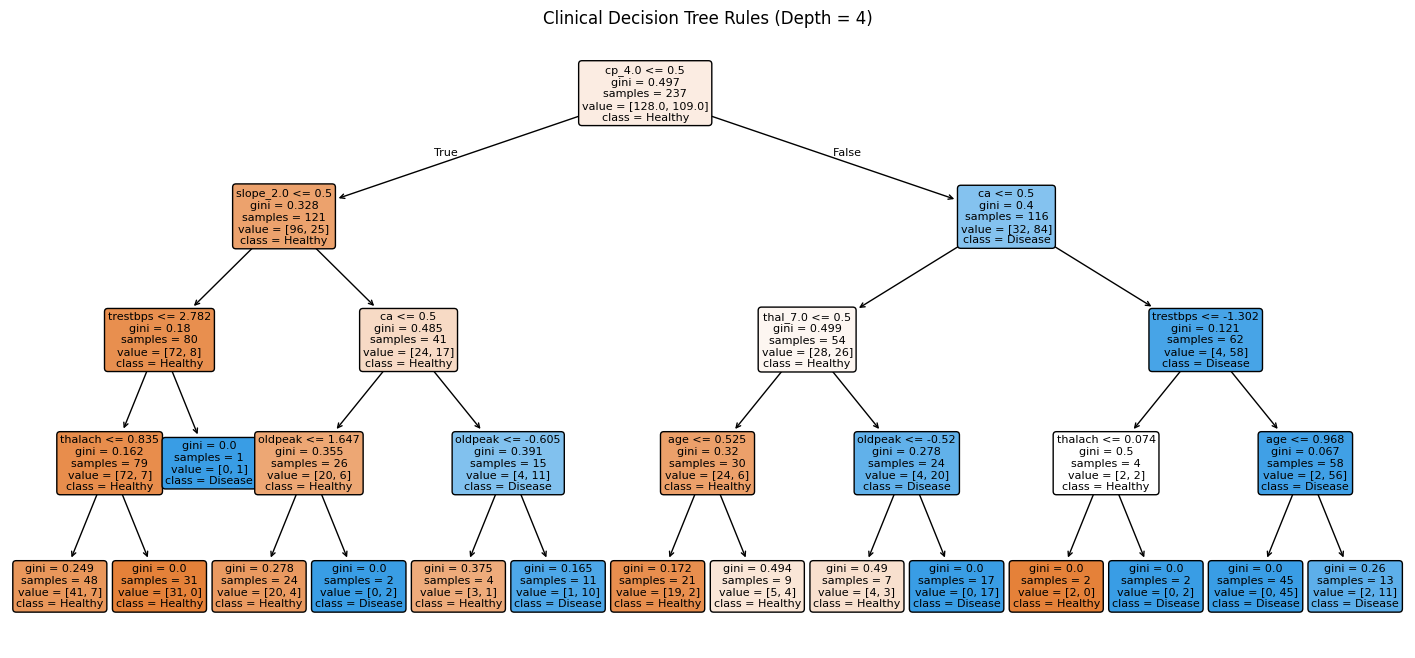

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(
    models["Decision Tree"],
    feature_names=X_train.columns.tolist(),
    class_names=["Healthy", "Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Clinical Decision Tree Rules (Depth = 4)")
plt.show()

In [ ]:
rf_proba = probas["Random Forest"]
p, r, thresholds = precision_recall_curve(y_test, rf_proba)

# Find optimal threshold to maximize Recall while keeping Precision >= 80%
valid_idx = np.where(p[:-1] >= 0.80)[0]
best_idx = valid_idx[np.argmax(r[valid_idx])]
opt_threshold = thresholds[best_idx]

adjusted_preds = (rf_proba >= opt_threshold).astype(int)

print(f"Optimal Decision Threshold: tau = {opt_threshold:.3f}")
print("Precision: %.3f" % precision_score(y_test, adjusted_preds))
print("Recall:    %.3f" % recall_score(y_test, adjusted_preds))
print("F1-Score:  %.3f" % f1_score(y_test, adjusted_preds))
print("\nAdjusted Confusion Matrix:\n", confusion_matrix(y_test, adjusted_preds))

Optimal Decision Threshold: tau = 0.313
Precision: 0.800
Recall:    1.000
F1-Score:  0.889

Adjusted Confusion Matrix:
 [[25  7]
 [ 0 28]]
